In [1]:
import pandas as pd
from zipfile import ZipFile

with ZipFile("CSI300_Factor_Research_Data.zip") as z:
    prices = pd.read_csv(z.open("daily_prices.csv"), parse_dates=["date"])
    members = pd.read_csv(
        z.open("csi300_membership.csv"),
        parse_dates=["member_start", "member_end"],
    )
    dates = pd.read_csv(
        z.open("trading_calendar.csv"), parse_dates=["date"]
    )["date"]

# 转成宽表。每行是一个交易日，每列是一只股票。
close = prices.pivot(index="date", columns="code", values="adj_close")
close = close.reindex(dates)

# 用统一的交易日历确定每月最后一个交易日。
month_ends = dates.groupby(dates.dt.to_period("M")).max()
monthly_close = close.reindex(month_ends)

# 12–1 月动量。用上月末价格除以 12 个月前的月末价格，再减 1。
momentum = monthly_close.shift(1) / monthly_close.shift(12) - 1

# 60 日波动率。计算最近 60 个日收益率的标准差。
daily_returns = close.pct_change(fill_method=None)
volatility = daily_returns.rolling(60).std().reindex(month_ends)
factors = pd.concat(
    [
        momentum.stack().rename("momentum"),
        volatility.stack().rename("volatility"),
    ],
    axis=1,
).dropna().reset_index()

# 一只股票可能多次进出指数，所以按月末日期检查成分区间。
factors = factors.merge(members, on="code")
is_member = factors["date"].between(
    factors["member_start"], factors["member_end"]
)
factors = factors.loc[
    is_member, ["date", "code", "momentum", "volatility"]
].sort_values(["date", "code"])

assert not factors.duplicated(["date", "code"]).any()
factors.to_csv("monthly_factors.csv", index=False)

print(factors.shape)
print(factors.groupby("date").size().describe())
factors.head()

(24542, 4)
count     84.000000
mean     292.166667
std        7.192421
min      268.000000
25%      290.000000
50%      294.000000
75%      297.000000
max      300.000000
dtype: float64


,date,code,momentum,volatility
0,2019-01-31,SH600000,-0.247993,0.011996
1,2019-01-31,SH600004,-0.395245,0.020711
3,2019-01-31,SH600009,0.093402,0.017453
4,2019-01-31,SH600010,-0.403116,0.013365
5,2019-01-31,SH600011,0.187522,0.020436


In [2]:
# 在完整月末价格表上计算次月收益，再按日期和股票匹配。
next_returns = (
    (monthly_close.shift(-1) / monthly_close - 1)
    .stack()
    .rename("next_return")
    .reset_index()
)

panel = factors.merge(
    next_returns, on=["date", "code"], validate="one_to_one"
)

# 波动率越低，低波动因子得分越高。
panel["low_vol"] = -panel["volatility"]

rows = []
for date, group in panel.groupby("date"):
    rows.append({
        "date": date,
        "momentum_ic": group["momentum"].corr(
            group["next_return"], method="spearman"
        ),
        "low_vol_ic": group["low_vol"].corr(
            group["next_return"], method="spearman"
        ),
    })

ic = pd.DataFrame(rows).set_index("date")

print(f"有次月收益的样本行数：{len(panel):,}")
print(f"可检验的月份：{len(ic)}")
print(ic.mean().round(4))

ic.head()

有次月收益的样本行数：24,215
可检验的月份：83
momentum_ic    0.0390
low_vol_ic     0.0507
dtype: float64


,momentum_ic,low_vol_ic
date,,
2019-01-31,-0.424612,-0.541510
2019-02-28,0.016868,-0.194996
2019-03-29,0.280956,0.342660
2019-04-30,0.223498,0.328598
2019-05-31,0.261403,-0.076610


In [3]:
scores = factors.assign(low_vol=-factors["volatility"])
results = {}

for factor in ["momentum", "low_vol"]:
    grouped = scores[["date", "code", factor]].sort_values(["date", "code"]).copy()

    # G1 是因子得分最低的 20%，G5 是最高的 20%。
    grouped["group"] = grouped.groupby("date")[factor].transform(
        lambda x: pd.qcut(x.rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
    )

    grouped = grouped.merge(
        next_returns, on=["date", "code"], how="left", validate="one_to_one"
    )

    # 每月每组取次月收益的平均值，对应组内等权。
    monthly = (
        grouped.groupby(["date", "group"], observed=True)["next_return"]
        .mean()
        .unstack("group")
        .dropna(how="all")
    )
    monthly.columns = [f"G{g}" for g in monthly.columns]
    monthly["G5-G1"] = monthly["G5"] - monthly["G1"]
    results[factor] = monthly

summary = pd.DataFrame(
    {name: monthly.mean() * 100 for name, monthly in results.items()}
).round(3)
print("各组平均月收益（%），G5-G1 为百分点")
display(summary)

spreads = pd.DataFrame(
    {name: monthly["G5-G1"] for name, monthly in results.items()}
)
annual = spreads.groupby(spreads.index.year).mean() * 100
display(annual.round(3))

各组平均月收益（%），G5-G1 为百分点


,momentum,low_vol
G1,0.199,1.021
G2,0.528,0.880
G3,0.993,0.925
G4,1.112,0.534
G5,1.336,0.813
G5-G1,1.136,-0.208


,momentum,low_vol
date,,
2019,1.094,-3.202
2020,4.321,-2.549
2021,-0.571,1.189
2022,0.032,0.595
2023,1.723,4.945
2024,0.230,0.241
2025,1.126,-2.896


In [4]:
mom_spread = spreads["momentum"].dropna()

check = pd.DataFrame({
    "全样本": [
        mom_spread.mean() * 100,
        (mom_spread > 0).mean() * 100,
    ],
    "剔除2020年信号月份": [
        mom_spread[mom_spread.index.year != 2020].mean() * 100,
        (mom_spread[mom_spread.index.year != 2020] > 0).mean() * 100,
    ],
}, index=["平均月度价差（百分点）", "价差为正的月份占比（%）"])

display(check.round(3))

,全样本,剔除2020年信号月份
平均月度价差（百分点）,1.136,0.598
价差为正的月份占比（%）,60.241,60.563


各组合平均月收益（%）及月均超额（百分点）
Momentum_G5      1.336
Universe_EW      0.835
excess_return    0.501
dtype: float64
G5 跑赢等权的月份占比（%）
56.63


<Axes: title={'center': 'Momentum G5 vs. Equal-Weighted Universe'}, xlabel='date', ylabel='Growth of 1'>

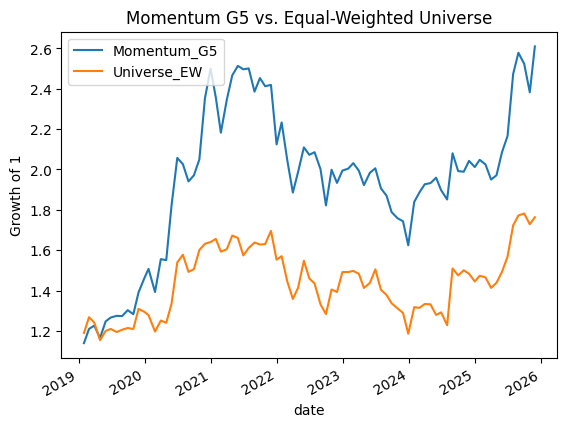

In [5]:
comparison = pd.concat(
    [
        results["momentum"]["G5"].rename("Momentum_G5"),
        panel.groupby("date")["next_return"].mean().rename("Universe_EW"),
    ],
    axis=1,
).dropna().sort_index()

comparison["excess_return"] = (
    comparison["Momentum_G5"] - comparison["Universe_EW"]
)

print("各组合平均月收益（%）及月均超额（百分点）")
print((comparison.mean() * 100).round(3))
print("G5 跑赢等权的月份占比（%）")
print(round((comparison["excess_return"] > 0).mean() * 100, 2))

nav = (1 + comparison[["Momentum_G5", "Universe_EW"]]).cumprod()
nav.plot(title="Momentum G5 vs. Equal-Weighted Universe", ylabel="Growth of 1")

In [6]:
returns = comparison[["Momentum_G5", "Universe_EW"]]
growth = (1 + returns).cumprod()

# 从初始净值 1 开始计算峰值，首月的亏损也会计入回撤。
peak = growth.cummax().clip(lower=1.0)
drawdown = growth / peak - 1

performance = pd.DataFrame({
    "累计收益（%）": (growth.iloc[-1] - 1) * 100,
    "年化收益（%）": (growth.iloc[-1] ** (12 / len(returns)) - 1) * 100,
    "年化波动率（%）": returns.std() * (12 ** 0.5) * 100,
    "最大回撤（%）": drawdown.min() * 100,
})

display(performance.round(2))

,累计收益（%）,年化收益（%）,年化波动率（%）,最大回撤（%）
Momentum_G5,160.99,14.88,20.82,-35.38
Universe_EW,76.34,8.55,19.48,-30.07


,Mean Rank IC,Rank IC Std,Monthly ICIR
momentum_ic,0.0390,0.2312,0.1686
low_vol_ic,0.0507,0.2668,0.1901


,momentum_ic,low_vol_ic,Months
date,,,
2019,0.0506,-0.0635,12
2020,0.1182,-0.0368,12
2021,-0.0570,0.1014,12
2022,0.0123,0.0398,12
2023,0.0982,0.2310,12
2024,0.0306,0.0816,12
2025,0.0182,-0.0030,11


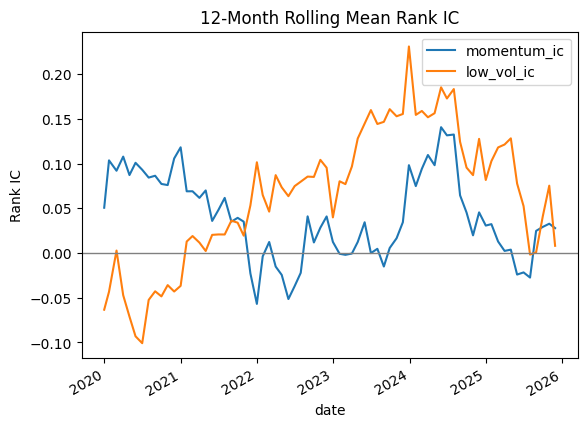

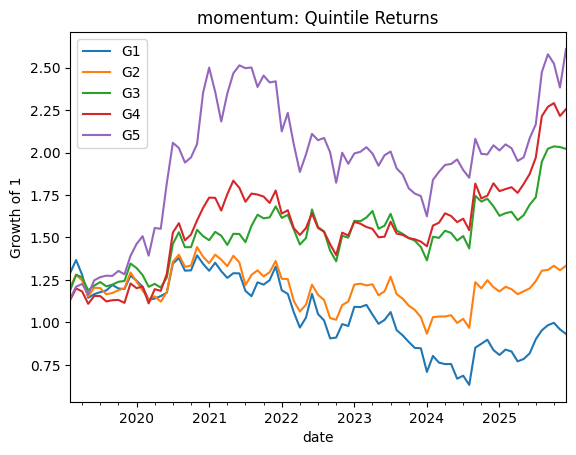

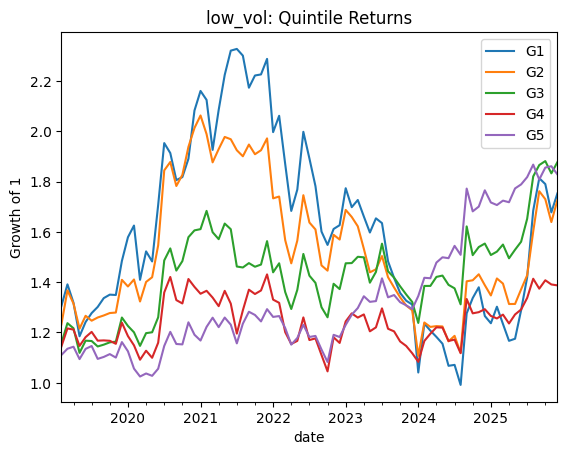

In [7]:
# 月频 ICIR = 月度 Rank IC 均值 / 月度 Rank IC 样本标准差
ic_summary = pd.DataFrame({
    "Mean Rank IC": ic.mean(),
    "Rank IC Std": ic.std(),
    "Monthly ICIR": ic.mean() / ic.std(),
})
display(ic_summary.round(4))

# 按信号年份汇总，同时报告月份数
annual_ic = ic.groupby(ic.index.year).mean()
annual_ic["Months"] = ic.groupby(ic.index.year).size()
display(annual_ic.round(4))

ax = ic.rolling(12).mean().plot(
    title="12-Month Rolling Mean Rank IC", ylabel="Rank IC"
)
ax.axhline(0, color="gray", linewidth=1)

groups = ["G1", "G2", "G3", "G4", "G5"]
for name, monthly in results.items():
    returns_by_group = monthly[groups].copy()
    # 收益发生在信号形成后的下一个月，横轴标为持有月份。
    returns_by_group.index = (
        returns_by_group.index.to_period("M") + 1
    ).to_timestamp(how="end").normalize()
    wealth = (1 + returns_by_group).cumprod()
    wealth.plot(title=f"{name}: Quintile Returns", ylabel="Growth of 1")